# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [26]:



# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




In [27]:

# cargar archivos
plans = pd.read_csv('/content/plans.csv')
usage = pd.read_csv('/content/usage.csv')
users = pd.read_csv('/content/users_latam.csv')



In [28]:




# mostrar las primeras 5 filas de plans
plans.head()





,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [29]:

# mostrar las primeras 5 filas de users
users.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [30]:



# mostrar las primeras 5 filas de usage
usage.head()




,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [31]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [32]:


# inspección de plans con .info()
plans.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [33]:

# inspección de users con .info()
users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [34]:

# inspección de usage con .info()
usage.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [35]:



# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos
print(users.isna().mean())# Proporción de valores nulos




user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [36]:

# cantidad de nulos para usage
print(usage.isna().sum()) # Cantidad de valores nulos
print(usage.isna().mean())# Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
**- ¿Qué columnas tienen valores faltantes y en qué proporción?**
   La columna City contiene un 11.73% de valores faltantes lo que afectaria el análisis geografico.
  La columna churn_date contien un 88.35% de valores faltantes.

  
**Indica qué harías: ¿imputar, eliminar, ignorar?**
- En el caso de la columna City se recomienda conservar los regustirso y colocar una descripción a los campos vacios para evitar perder la información del cliente;
- Por otro lado la columna de Churn_date se debería validar que ocurre con esta columna ya que pueden ser clientes que aun no se han dado de baja en el servicio, teniendo tambien en cuenta que por metodología al ser una columna con mas del 80% de valores nulos se debería ignorar, sin embargo deberia validarse primero con el equipo.
- En el caso de la columna date hay 50 registros vacios por lo que seria importante validar que ocurrio con la obtención de esos valores, la columna duration tienen un 55.19% lo cual corresponde a 22076 registros sin información, deberia revisar que ocurrio con estos valores, de lo contrario  se marcaran como valores faltantes NaT
- En cuanto a la columna length hay 17896 registros vacios lo cual representa un 44.74% de la muestra, deberia tambien validarse que ocurrio con esta información antes de procesarla o definir su tratamiento.
- Las demas columnas no presentan valores faltantes.



### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [37]:

# explorar columnas numéricas de users
users.describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` no presenta novedades en cuanto a sus registros ya que es un contador de la cantidad de clientes
- La columna `age` si tiene un valor atipico que es el minimo (-999) el cual puede relacionarse a edades desconocidas de los clientes; para este caso se recomienda evaluar la cantidad de registros y ver algun proceso de modo que no se distorcione la estadistica del campo.

In [38]:

# explorar columnas numéricas de usage
usage.describe()


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` no presenta valores atipicos como lo pueden ser los negativos y la columna  `user_id` coincide con lo que se visualiza en el dataset de users.
- Las columnas `duration` y `length` tienen valores maximos demasiado alejados de la mediana pero no significa que esten mal, hay que revisarlos con mayor detalle para poder determinar su funcionalidad.

In [39]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(f"\nColumna: {columna}")
    print(users[columna].value_counts(dropna=False))



Columna: city
city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: count, dtype: int64

Columna: plan
plan
Basico     2595
Premium    1405
Name: count, dtype: int64


- La columna `city` tiene 469 valores nulos lo cual significa que son clientes sin ciudades registradas y ademass de ello tiene 96 registros con el valor ? el cual parece ser un sentinel para representar valores de ciudades desconocidas, asi que seria un total de 565 clientes que no tienen una ciudad determinada.
- La columna `plan` no cuenta con valores nulos ni con sentinels.

In [40]:


# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)



,count
type,
text,22092
call,17908


- La columna `type` tampoco presentan sentinels ni valores vacios.








---

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- Se encontraron valores invalidos en la columna de age donde se visualizan valores como -999 y en la columna de city tenemos algunos campos vacios y un sentinel de ?, en el resto de columnas no se evidencia falta de información o información con valores atipicos.
- ¿Qué acción tomarías?
- Para la columna age se debe reemplazar los valores -999 y deberia imputarse la mediana y en la columna de City se unificara las columnas con valores nulos y sentiles (?) reemplazandola por "pd.NA".








### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.


**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).


Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [41]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [42]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')


In [43]:

# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

,count
reg_date,
2022,1314
2023,1316
2024,1330
2026,40


In [44]:
usage['date'].dt.year.value_counts(dropna=False).sort_index()

,count
date,
2024.0,39950
NaN,50




-Se visualiza que hay 40 datos correspondientes al 2026 lo cual no corresponde a la información brindada en el proyecto donde se comunicaba que se trabajaria con información hasta el año 2024.
- Se visualiza que hay 50 datos sin fecha en la columna date, lo cual se recomienda validar para ver si es posible recuperar estos datos, de no ser asi se marcaran como valores faltantes NaT



In [45]:

# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()


,count
date,
2024.0,39950


En `date`, ... haz doble clic en este bloque y escribe qué ves.

- Se visualiza que hay 39950 registros del año 2024, sin embargo 50 registros no tienen una fecha definida.
Basaremos el análisis en estas fechas.




- En reg_date validaria los  registros que tienen asociada la fecha de  ya que pudo ser un error en la recopilacion de los datos, de no ser asi lo eliminariamos del análisis.
- Con los 50 registros que no tienen información de las fechas tambien revisaria que se puede validar, de no ser asi se marcaran como valores nulos NaT







    


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.




✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Si en la columna de reg_date hay 40 registros del 2026 que no coinciden con el periodo de información el cual va hasta el 2024 y tambien la columna de date tienen 50 registros vacios los cuales no tienen un año asociado.
- ¿Qué harías con ellas?
- Se reemplazaron los 40 registros por valores nulos (Nat), ademas de ello se corrigio los valores erroneos de age (-999), en este caso se utilizo la mediana del resto de edades y para el sentinel de ? en la columna de city se reemplazo por valores nulos, teniendo en total 565 registros sin una ciudad asociada.




In [46]:


# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()



,age
count,4000.000000
mean,48.136000
std,17.689919
min,18.000000
25%,33.000000
50%,48.000000
75%,63.000000
max,79.000000


In [47]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
users['city'].isna().sum()

np.int64(565)

In [48]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts().sort_index()



,count
reg_date,
2022.0,1314
2023.0,1316
2024.0,1330


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [49]:



# Verificar la proporción de nulos en duration y length según type
usage[['duration', 'length']].isna().groupby(usage['type']).mean() * 100



,duration,length
type,,
call,0.000000,99.932991
text,99.927576,0.000000



Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
- Se confirma que los valores nulos de las columnas dependen de la columna type asi que esto confirma que son de tipo MAR, se conservan por que duration solo aplica a llamadas y length a text, por lo que no requieren tratamiento adicional.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [50]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# Observar resultado
usage_agg.head(3)



,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [51]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns=
{ "is_text": "cant_mensajes",
  "is_call": "cant_llamadas",
  "duration": "cant_minutos_llamada"  })
# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [52]:
# Combinar las tablas conservando todos los usuarios
user_profile = pd.merge(
    users,
    usage_agg,
    on='user_id',
    how='left')
columnas_uso = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada']
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)
# Verificar el resultado
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [53]:

# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [54]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

,proportion
plan,
Basico,64.875
Premium,35.125


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

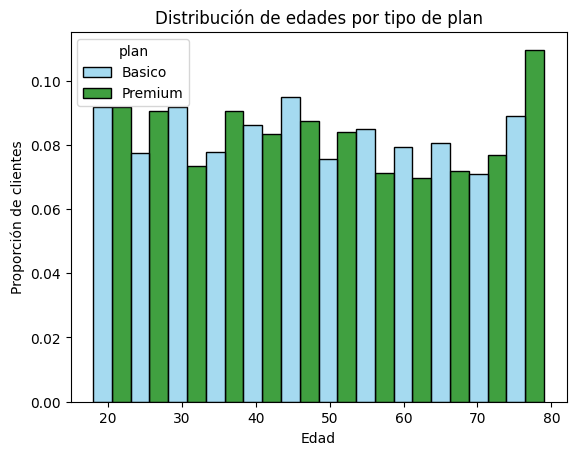

In [55]:
# Distribución de edades por tipo de plan
sns.histplot(data=user_profile, x='age', hue='plan',
             palette=['skyblue', 'green'],
             stat='probability', common_norm=False,
             multiple='dodge', bins=12)

plt.title('Distribución de edades por tipo de plan')
plt.xlabel('Edad')
plt.ylabel('Proporción de clientes')
plt.show()




💡Insights:
- La distribución por edad es relativamente similar entre las edades entre los 18 años y los 79 años, a nivel de planes tambien se visualiza un patron similar donde el pico se concentra en los clientes con edades cercanas a los 50 años, este no es consecunecia de la imputacion de los 55 registros con -999 por la mediana




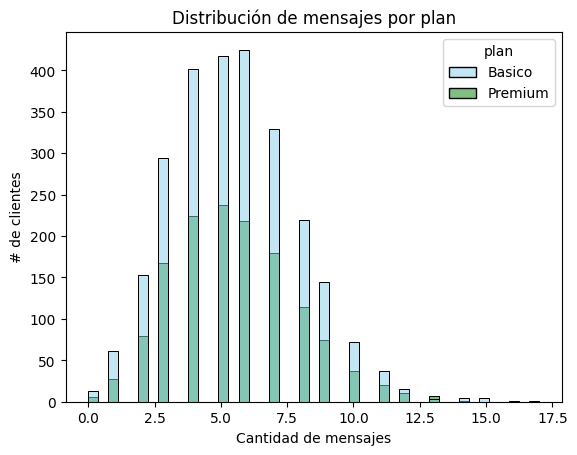

In [56]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan',
             palette=['skyblue', 'green'])
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('# de clientes')
plt.show()




💡Insights:
- El top de mensajes esta concentrado entre 3 y 7 mensajes en ambos planes, se observa un pequeño sesgo a la derecha esto asociado a clientes que suelen mandar mas cantidad de mensajes que la mediana de los clientes.



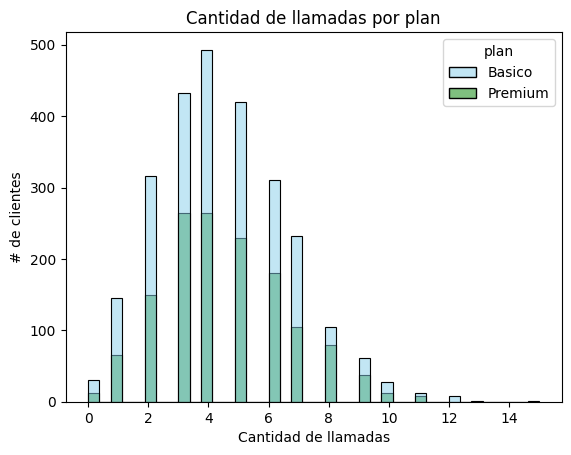

In [57]:
# Histograma para visualizar la cantidad de llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan',
             palette=['skyblue', 'green'])
plt.title('Cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('# de clientes')
plt.show(
)

💡Insights:
- La cantidad de llamadas por cliente se concentra en ambos tipos de plan entre las 2 y las 6 llamadas, donde el pico en el plan basico son 4 llamadas y en el plan premium esta entre 3 y 4 llamadas, hay un ligero sesgo hacia la derecha.

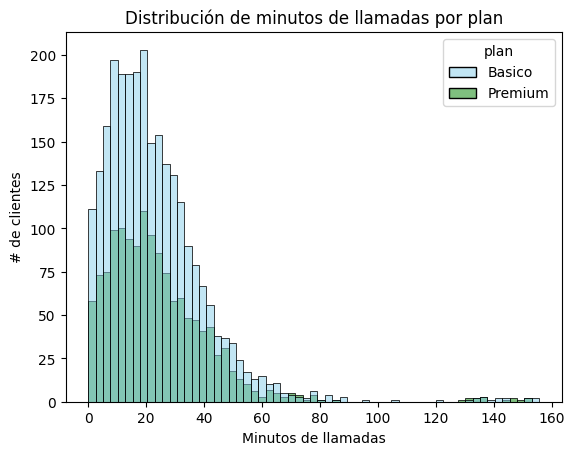

In [58]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan',
             palette=['skyblue', 'green'])
plt.title('Distribución de minutos de llamadas por plan')
plt.xlabel('Minutos de llamadas')
plt.ylabel('# de clientes')
plt.show()




💡Insights:
- La distribución de los minutos presenta un sesgo a la derecha, donde la mayoria de clientes se concentra en un consumo entre los 5 y 40 minutos, mientras que otro grupo registra consumo superior llegando hasta 150 minutos.



### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

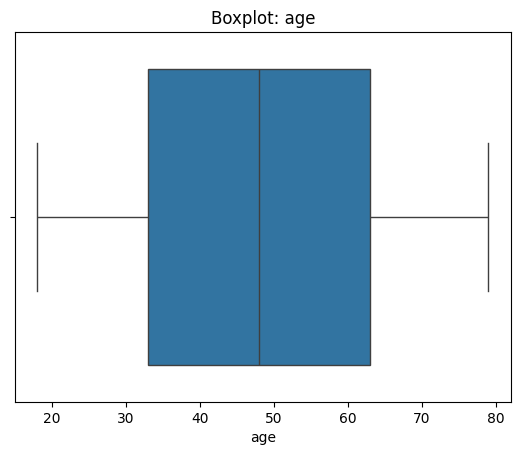

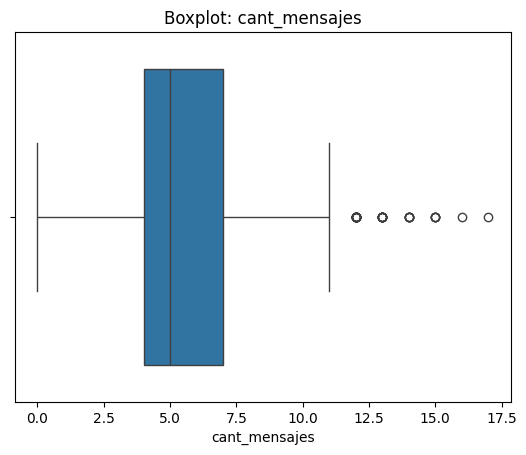

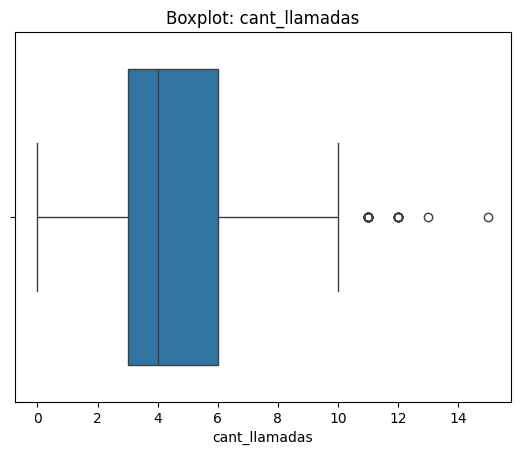

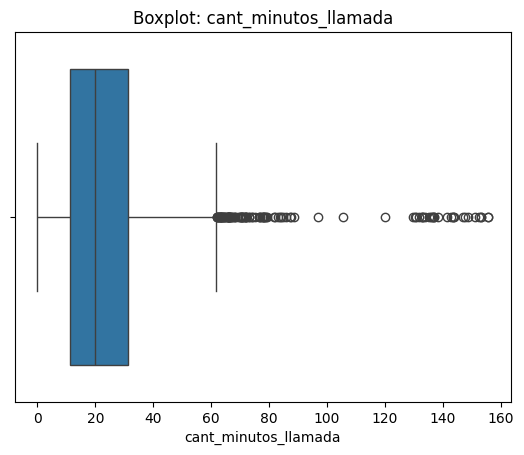

In [59]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights:
- Age: No presenta Outliers la mediana esta cerca a los 50 años
- cant_mensajes: presenta outliers a partir de los 12 mensajes llegando hasta valores de 17 mensajes.
- cant_llamadas: presenta outliers despues de las 11 llamadas.
- cant_minutos_llamada: presenta outliers despues de 60 minutos llegando hasta valores de 160 minutos.


In [60]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    print(col, "Límite superior:", limite_superior)
    print("Cantidad de outliers:",
          (user_profile[col] > limite_superior).sum())



cant_mensajes Límite superior: 11.5
Cantidad de outliers: 46
cant_llamadas Límite superior: 10.5
Cantidad de outliers: 30
cant_minutos_llamada Límite superior: 61.870000000000005
Cantidad de outliers: 109


In [61]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000




💡Insights:
- cant_mensajes: mantener o no outliers, porqué?
- Recomiendo mantenerlos ya que puede ser que sean clientes con mayor envio de mensajes y no son demasiados para pensar que puede ser un error, ademas de que los valores no estan tan alejados de la mediana.
- cant_llamadas: mantener o no outliers, porqué?
- Recomiendo conservarlos ya que son 30 registros que superan el limite de las 10 llamadas, teniendo como valor maximo 15.
- cant_minutos_llamada: mantener o no outliers, porqué?
- Se podria revisar aunque estos clientes pueden ser valiosos ya que son aquellos que realizan un alto consumo de minutos durante las llamads, sin embargo seria bueno revisarlo con el equipo, asi que se recomienda mantener estos outliers por que podria representar clientes con consumos elevados lo cual es valioso para la compañia.



---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [62]:

# Crear columna grupo_uso

variables = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)]
grupo_uso = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(
    variables,
    grupo_uso,
    default='Alto uso'
)


In [63]:
# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [64]:


# Crear columna grupo_edad
variables = [
    user_profile['age'] < 30,
    user_profile['age'] < 60]
grupo_edad = ['Joven', 'Adulto']
user_profile['grupo_edad'] = np.select(
    variables,
    grupo_edad,
    default='Adulto Mayor'
)



In [65]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

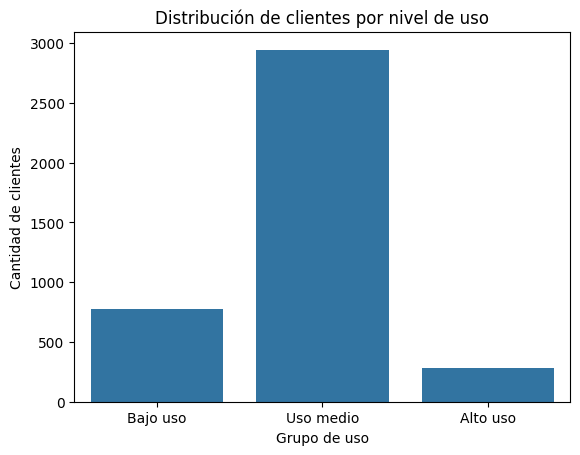

In [68]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso',
              order=['Bajo uso', 'Uso medio', 'Alto uso'])

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()

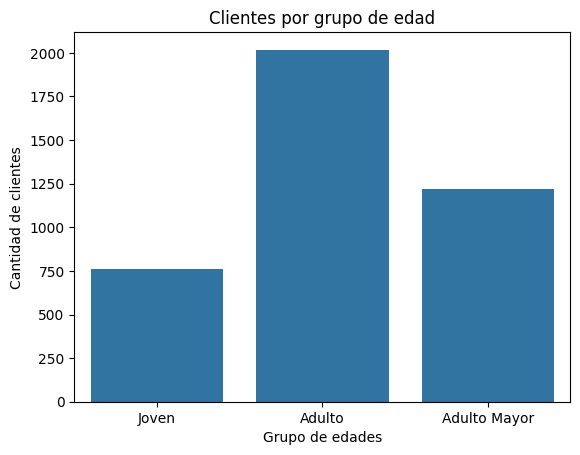

In [67]:


# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])

plt.title('Clientes por grupo de edad')
plt.xlabel('Grupo de edades')
plt.ylabel('Cantidad de clientes')
plt.show()




---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Análisis ejecutivo de la empresa de telecomunicaciones ConnectaTel:**


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Se trabajo con una base de 4000 clientes donde se identificaron algunos columnas sin información:
City: son 565 (14% de la muestra) registros de clientes que no contienen un valor (469 nulos + 96 "?")
ademas de ello se detectaron edades incorrecta como -999 (55 registros) las cuales fueron reemplazadas dentro de la base por la mediana de la columa edad, otra columna que se identifico fue la de fecha donde cerca de 40 registros contenian información del año 2026 lo cual es incorrecto ya que se preciso que se tendria información hasta el 2024.
Tambien se identificaron valores nulos para las columnas de duration y de lenght los cuales se conservaron por que eran valores que dependian del tipo de servicio ya fuera llamadas o mensajes de texto.

🔍 **Segmentos por Edad**
Se identificaron 3 segmentos de clientes, jovenes los cuales eran personas con menos de 30 años, adultos que eran personas entre los 30 años y los 59 años y adultos mayores que son las personas con 60 años o mas,donde la mayoria de los clientes se concentra en personas del grupo "Adultos", no se detectaron valores atipicos ni diferencias marcadas entre los tipos de planes (Revisar histograma Distribución de edades por tipo de plan)

📊 **Segmentos por Nivel de Uso**
Se realizó la clasificación por segmento de uso en las siguientes 3 categorías:
- **Bajo Uso:** Son aquellos clientes que realizan menos de 5 llamadas y mensajes
- **Uso Medio:** Son donde se concentra la mayoría de la muestra (ver distribución de clientes por nivel de uso), donde presentan consumos mayores a las 5 llamads y mensajes pero menor a 10.
- **Uso Alto:** Es el grupo de menor participación, sin embargo son el grupo mas importante para la compañia, ya que son clientes recurrentes en el uso de los servicios de comunicación.
➡️ Esto sugiere que ... el segmento de clientes de uso alto son los mas valioso para ConnectaTel, ya que son aquellos clientes con una mejor actividad de llamadas y mensajes, por lo que se pueden considerar como clientes de alto valor comercial.
Aquellos clientes que tienen outliers, pueden reflejar un consumo mayor y no necesariamente un eror, es por ello que se recomienda mantener estos registros y analizar otros comportamientos dentro del negocio, como fidelizar el cliente o mejorar el plan.


💡 **Recomendaciones**
- Se recomienda analizar los planes que contratan las personas que tienen un bajo uso de manera que se cumpla con sus necesidades de comunicación.
- Se recomienda analizar si los clientes cuentan con el plan adecuado de acuerdo al uso que le dan a nivel de llamadas y de mensajes ya que se pueden detectar oportunidades que generen un mejor rendimiento a la compañia al momento de brindarle unos planes con mejor cobertura.
- Es importante revisar esos patrones de clientes que tienen un consumo diferente a la mediana ya que pueden brindar información relevante o hipotesis sobre el negocio.
- Se debe implementar cierto control sobre la información que se recopila de los clientes, ya que es de suma importancia al momento de realizar una segmentación por ciudad, entender si el consumo de las llamadas esta enfocado en fechas punutales y demas metricas que permitan entender la realidad del negocio.



---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`


https://github.com/Sergio365leon/ConnectaTel-Project
